<a href="https://colab.research.google.com/github/dilrabo815/lung-nodule-degradation-screening/blob/main/progress_run_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Degradation-aware lung nodule malignancy screening — progress run (Colab GPU)

**Runtime → Change runtime type → GPU (T4 is enough; L4/A100 is ~2–3× faster).**

What this notebook does, top to bottom (≈ 2–2.5 h on a T4, mostly unattended):

| step | what | time (T4) |
|---|---|---|
| 1 | GPU check, clone repo, install | 1 min |
| 2 | unit + end-to-end smoke tests on synthetic data | 3 min |
| 3 | download LUNA25 annotations + nodule blocks (6.8 GB) + I3D weights | 10–20 min |
| 4 | data audit, patient-level split, crop cache | 15–25 min |
| 5 | train `baseline`, `aug`, `directional` (+ optional `symmetric`) | 60–90 min |
| 6 | evaluate: clean + 8 held-out degradations, referral at 80 % coverage | 10–15 min |
| 7 | figures + `headline.json` → zipped to Drive for the slides | 1 min |

Checkpoints and results are written to **Google Drive**, so a disconnect loses at most the current run.

In [1]:
# 1a. GPU + Drive
!nvidia-smi --query-gpu=name,memory.total --format=csv
from google.colab import drive
drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/lungdeg'          # results survive disconnects here
ROOT = '/content/luna25'                          # fast local disk for data + cache
!mkdir -p {DRIVE}/runs {DRIVE}/raw {ROOT}
!ln -sfn {DRIVE}/runs {ROOT}/runs

name, memory.total [MiB]
Tesla T4, 15360 MiB
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# 1b. Fill these 3 lines once, then Run all.
GITHUB_USER  = 'dilrabo815'                 # the account the repo lives on
GITHUB_EMAIL = 'd.orziqulova@newuu.uz'
REPO_NAME    = 'lung-nodule-degradation-screening'
# Add a Colab secret (key icon on the left) named GH_TOKEN = a GitHub token with
# 'repo' scope (github.com/settings/tokens). Needed to clone a private repo and to
# push the results back at the end.
import os
from google.colab import userdata
tok = userdata.get('GH_TOKEN')
url = f'https://{tok}@github.com/{GITHUB_USER}/{REPO_NAME}.git'
if not os.path.exists('/content/repo'):
    !git clone -q {url} /content/repo
else:
    !git -C /content/repo pull -q
!git -C /content/repo config user.name "{GITHUB_USER}"
!git -C /content/repo config user.email "{GITHUB_EMAIL}"
!pip -q install -e /content/repo pytest
%cd /content/repo

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for lungdeg (pyproject.toml) ... done
/content/repo


## 2. Tests (fail fast before spending GPU time)

In [3]:
!python -m pytest -q -m "not slow"
!python -m pytest -q -m slow -x     # trains 2 tiny models on synthetic crops, evaluates, builds report

..................                                                       [100%]
18 passed, 1 deselected in 7.48s
.                                                                        [100%]
1 passed, 18 deselected in 41.17s


## 3. Data download
Zip parts are kept on Drive after the first download (6.8 GB of the 15 GB free quota), so later sessions skip this step.

In [4]:
!apt-get -qq install -y p7zip-full > /dev/null
!mkdir -p {ROOT}/raw && cp -n {DRIVE}/raw/* {ROOT}/raw/ 2>/dev/null; ls -la {ROOT}/raw
!python -m lungdeg.data.download --root {ROOT}
KEEP_RAW_ON_DRIVE = True
if KEEP_RAW_ON_DRIVE:
    !cp -n {ROOT}/raw/*.zip.00* {ROOT}/raw/*.csv {ROOT}/raw/model_rgb.pth {DRIVE}/raw/

total 6688064
drwxr-xr-x 2 root root       4096 Oct 27 15:55 .
drwxr-xr-x 5 root root       4096 Oct 27 15:58 ..
-rw------- 1 root root 4697620480 Oct 27 15:55 luna25_nodule_blocks.zip.001
-rw------- 1 root root 2099185052 Oct 27 15:55 luna25_nodule_blocks.zip.002
-rw------- 1 root root     860931 Oct 27 15:55 LUNA25_Public_Training_Development_Data.csv
-rw------- 1 root root   50887222 Oct 27 15:55 model_rgb.pth
[skip] LUNA25_Public_Training_Development_Data.csv already present (0.00 GB)
annotation md5 1349fcd9fdd120a990f43a2301f1609b OK
[skip] model_rgb.pth already present (0.05 GB)
[skip] luna25_nodule_blocks.zip.001 already present (4.70 GB)
[skip] luna25_nodule_blocks.zip.002 already present (2.10 GB)
$ 7z x -y -o/content/luna25/nodule_blocks /content/luna25/raw/luna25_nodule_blocks.zip.001

7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan /content/luna25/raw/

In [5]:
   !ls -lh {DRIVE}/raw

total 6.4G
-rw------- 1 root root 4.4G Oct 26 15:39 luna25_nodule_blocks.zip.001
-rw------- 1 root root 2.0G Oct 26 15:39 luna25_nodule_blocks.zip.002
-rw------- 1 root root 841K Oct 26 15:39 LUNA25_Public_Training_Development_Data.csv
-rw------- 1 root root  49M Oct 26 15:39 model_rgb.pth


## 4. Audit, patient-level split (70/15/15, dev → head_fit/calib/thresh), crop cache
The split CSV and audit JSON are copied to Drive — **these files go in the repo** (`splits/`) so every member uses the same split.

In [6]:
!python -m lungdeg.prepare --root {ROOT} --seed 2025 --workers 2
!mkdir -p {DRIVE}/splits && cp {ROOT}/splits/* {DRIVE}/splits/
import json, pandas as pd
print(json.dumps(json.load(open(f'{ROOT}/splits/data_audit.json')), indent=1)[:3000])

columns used: {'patient': 'PatientID', 'series': 'SeriesInstanceUID', 'annotation': 'AnnotationID', 'nodule': 'NoduleID', 'label': 'label', 'study_date': 'StudyDate', 'age': 'Age_at_StudyDate', 'gender': 'Gender'}
{
  "observations": 6163,
  "malignant": 555,
  "benign": 5608,
  "patients": 2120,
  "series": 4069,
  "nodules": 3762,
  "duplicate_annotation_ids": 0,
  "obs_per_nodule": {
    "1": 2159,
    "2": 805,
    "3": 798
  },
  "nodules_with_repeats": 1603,
  "nodules_with_conflicting_labels": 0,
  "patients_with_both_classes": 0,
  "imbalance_ratio_benign_per_malignant": 10.1,
  "rows_with_missing_values": 0,
  "age_mean_by_label": {
    "0": 63.3,
    "1": 64.0
  },
  "missing_block_files": 0,
  "missing_block_examples": [],
  "block_shapes": {
    "(64, 128, 128)": 6163
  },
  "slice_spacing_mm_quantiles": [
    0.5,
    1.8,
    2.0,
    2.0,
    3.2
  ],
  "inplane_spacing_mm_quantiles": [
    0.46,
    0.61,
    0.66,
    0.7,
    0.98
  ],
  "thick_slices_ge_2mm": 4224,
 

## 5. Training
Same I3D, same hyper-parameters (official baseline: Adam 1e-4, wd 5e-4, batch 32, 10 epochs, ±20° rotation, 2.5 mm shift).
Only the training objective differs. Set `RUN_SYMMETRIC=False` if GPU time is short — it is the ablation, not needed for this week's comparison.

In [7]:
import subprocess, sys
EPOCHS = 10
SEED = 2025
RUN_SYMMETRIC = True
methods = ['baseline', 'aug', 'directional'] + (['symmetric'] if RUN_SYMMETRIC else [])
for m in methods:
    out = f'{ROOT}/runs/{m}_s{SEED}'
    if os.path.exists(f'{out}/best.json'):
        print('already trained:', m); continue
    print(f'===== {m} =====', flush=True)
    !python -m lungdeg.train --root {ROOT} --method {m} --seed {SEED} --epochs {EPOCHS} --workers 2

===== baseline =====
train 4364 obs (392 malignant) | dev 878 obs (82 malignant) | device cuda
epoch 1 | train_bce_clean 0.5365 | train_loss 0.5365 | train_seconds 52.0000 | dev_loss 0.8902 | dev_auroc 0.8273 | dev_loss_deg 0.8951 | dev_auroc_deg 0.8275 | dev_malignant_logit_drop -0.1448
epoch 2 | train_bce_clean 0.3961 | train_loss 0.3961 | train_seconds 49.4000 | dev_loss 0.3435 | dev_auroc 0.8572 | dev_loss_deg 0.3415 | dev_auroc_deg 0.8451 | dev_malignant_logit_drop 0.0996
epoch 3 | train_bce_clean 0.3240 | train_loss 0.3240 | train_seconds 51.5000 | dev_loss 0.5798 | dev_auroc 0.8704 | dev_loss_deg 0.4692 | dev_auroc_deg 0.8566 | dev_malignant_logit_drop 0.6185
epoch 4 | train_bce_clean 0.2683 | train_loss 0.2683 | train_seconds 52.1000 | dev_loss 0.4855 | dev_auroc 0.8464 | dev_loss_deg 0.3895 | dev_auroc_deg 0.8319 | dev_malignant_logit_drop 0.6820
epoch 5 | train_bce_clean 0.2351 | train_loss 0.2351 | train_seconds 52.4000 | dev_loss 0.6471 | dev_auroc 0.8499 | dev_loss_deg 0.6

## 6. Evaluation (no test label is used for any threshold, temperature or head)

In [8]:
for m in methods:
    run = f'{ROOT}/runs/{m}_s{SEED}'
    if os.path.exists(f'{run}/test_referral.csv'):
        print('already evaluated:', m); continue
    !python -m lungdeg.evaluate --root {ROOT} --run {run} --tta 4 --n_boot 1000

[clean] AUROC 0.850 (0.794-0.903)  sens 0.889 spec 0.617
[thick_k3] AUROC 0.849 (0.793-0.901)  sens 0.877 spec 0.663
[thick_k5] AUROC 0.849 (0.793-0.902)  sens 0.840 spec 0.721
[lowres_k2] AUROC 0.854 (0.804-0.903)  sens 0.852 spec 0.682
[lowres_k3] AUROC 0.844 (0.796-0.889)  sens 0.802 spec 0.735
[lowdose_60] AUROC 0.840 (0.785-0.891)  sens 0.877 spec 0.670
[lowdose_100] AUROC 0.826 (0.775-0.877)  sens 0.852 spec 0.664
[smooth_kernel] AUROC 0.840 (0.784-0.892)  sens 0.753 spec 0.775
[thick_k3+lowdose_60] AUROC 0.850 (0.796-0.900)  sens 0.840 spec 0.705
[clean] AUROC 0.852 (0.787-0.909)  sens 0.901 spec 0.661
[thick_k3] AUROC 0.841 (0.775-0.902)  sens 0.864 spec 0.676
[thick_k5] AUROC 0.819 (0.750-0.887)  sens 0.778 spec 0.730
[lowres_k2] AUROC 0.833 (0.767-0.893)  sens 0.877 spec 0.610
[lowres_k3] AUROC 0.814 (0.746-0.880)  sens 0.864 spec 0.586
[lowdose_60] AUROC 0.836 (0.772-0.896)  sens 0.827 spec 0.708
[lowdose_100] AUROC 0.807 (0.738-0.867)  sens 0.765 spec 0.721
[smooth_kernel] 

## 7. Report → Drive (send `lungdeg_report.zip` back for the slides)

{
  "runs": [
    "aug_s2025",
    "baseline_s2025",
    "directional_s2025",
    "symmetric_s2025"
  ],
  "clean_test": {
    "aug": {
      "auroc": 0.852,
      "auprc": 0.535,
      "sensitivity": 0.901,
      "specificity": 0.661,
      "auroc_ci_lo": 0.787,
      "auroc_ci_hi": 0.909
    },
    "baseline": {
      "auroc": 0.85,
      "auprc": 0.483,
      "sensitivity": 0.889,
      "specificity": 0.617,
      "auroc_ci_lo": 0.794,
      "auroc_ci_hi": 0.903
    },
    "directional": {
      "auroc": 0.85,
      "auprc": 0.49,
      "sensitivity": 0.926,
      "specificity": 0.569,
      "auroc_ci_lo": 0.784,
      "auroc_ci_hi": 0.909
    },
    "symmetric": {
      "auroc": 0.85,
      "auprc": 0.453,
      "sensitivity": 0.938,
      "specificity": 0.555,
      "auroc_ci_lo": 0.799,
      "auroc_ci_hi": 0.899
    }
  },
  "mean_auroc_heldout_degradations": {
    "aug": 0.823,
    "baseline": 0.844,
    "directional": 0.832,
    "symmetric": 0.833
  },
  "flr_mean_heldout": {


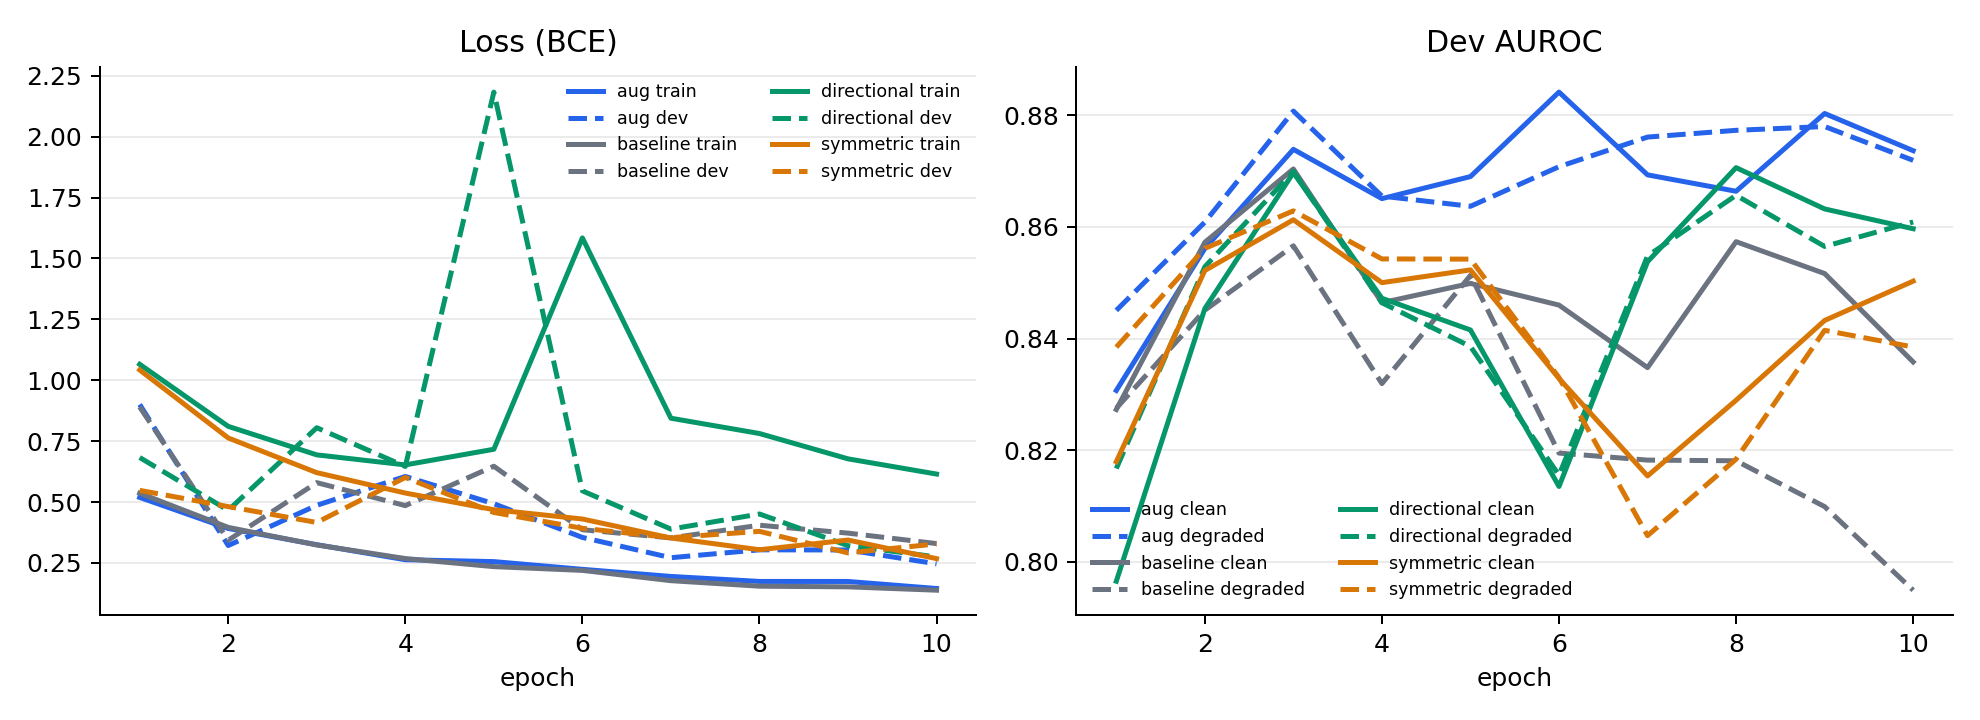

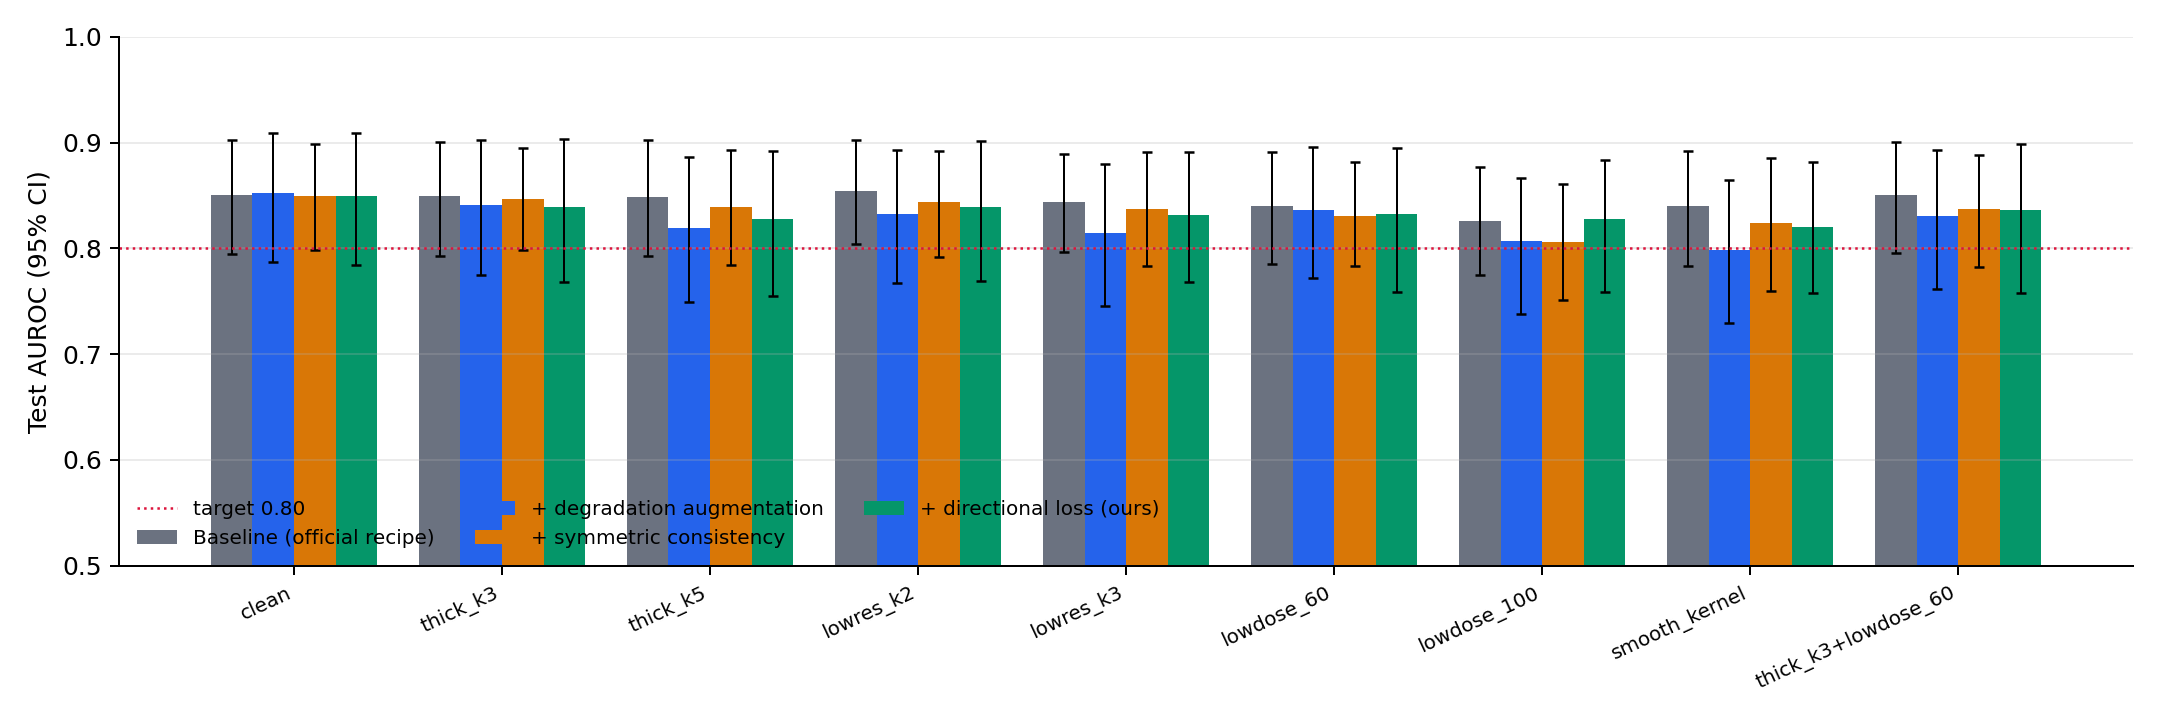

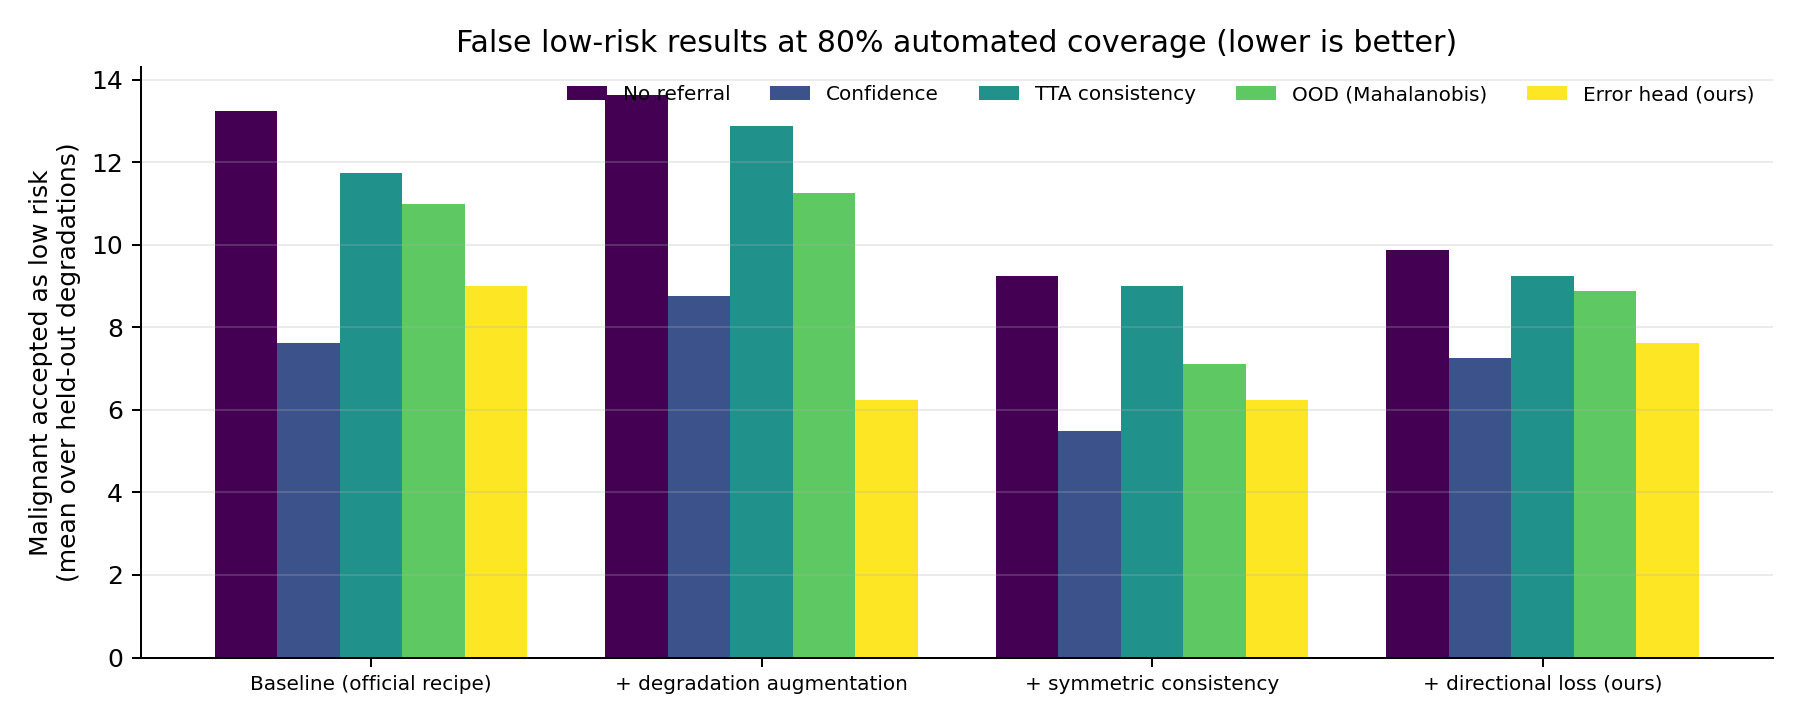

{
  "runs": [
    "aug_s2025",
    "baseline_s2025",
    "directional_s2025",
    "symmetric_s2025"
  ],
  "clean_test": {
    "aug": {
      "auroc": 0.852,
      "auprc": 0.535,
      "sensitivity": 0.901,
      "specificity": 0.661,
      "auroc_ci_lo": 0.787,
      "auroc_ci_hi": 0.909
    },
    "baseline": {
      "auroc": 0.85,
      "auprc": 0.483,
      "sensitivity": 0.889,
      "specificity": 0.617,
      "auroc_ci_lo": 0.794,
      "auroc_ci_hi": 0.903
    },
    "directional": {
      "auroc": 0.85,
      "auprc": 0.49,
      "sensitivity": 0.926,
      "specificity": 0.569,
      "auroc_ci_lo": 0.784,
      "auroc_ci_hi": 0.909
    },
    "symmetric": {
      "auroc": 0.85,
      "auprc": 0.453,
      "sensitivity": 0.938,
      "specificity": 0.555,
      "auroc_ci_lo": 0.799,
      "auroc_ci_hi": 0.899
    }
  },
  "mean_auroc_heldout_degradations": {
    "aug": 0.823,
    "baseline": 0.844,
    "directional": 0.832,
    "symmetric": 0.833
  },
  "flr_mean_heldout": {


In [9]:
!python -m lungdeg.report --root {ROOT} --out {DRIVE}/report
!cp {ROOT}/splits/data_audit.json {ROOT}/splits/split_seed2025_summary.json {DRIVE}/report/
!cd {DRIVE} && zip -qr lungdeg_report.zip report runs -x '*.pth' -x '*/preds/*'
from IPython.display import Image, display
for f in ['curves.png', 'auroc_by_condition.png', 'flr_at_coverage.png']:
    display(Image(f'{DRIVE}/report/{f}'))
print(open(f'{DRIVE}/report/headline.json').read())

## 8. Record everything in GitHub
Commits the split manifest, data audit, per-run configs and training histories, test metrics,
figures and `headline.json` into `results/` and pushes. Weights (`.pth`) and raw data are never committed.
After this cell, File → Save a copy in GitHub (or download) to also keep the executed notebook with its outputs.

In [10]:
import shutil, glob
R = '/content/repo/results'
os.makedirs(f'{R}/runs', exist_ok=True)
shutil.copytree(f'{ROOT}/splits', f'{R}/splits', dirs_exist_ok=True)
shutil.copytree(f'{DRIVE}/report', f'{R}/report', dirs_exist_ok=True)
for run in glob.glob(f'{ROOT}/runs/*_s*'):
    dst = f"{R}/runs/{os.path.basename(run)}"
    os.makedirs(dst, exist_ok=True)
    for f in ['config.json', 'history.json', 'best.json', 'posthoc.json', 'test_metrics.csv', 'test_referral.csv']:
        if os.path.exists(f'{run}/{f}'):
            shutil.copy(f'{run}/{f}', dst)
!cd /content/repo && git add results && git commit -q -m "Results: progress run (seed {SEED}) - splits, audit, curves, test metrics" && git push -q origin main && git log --oneline -3

355398d (HEAD -> main, origin/main, origin/HEAD) Results: progress run (seed 2025) - splits, audit, curves, test metrics
6da344f Results: progress run (seed 2025) - splits, audit, curves, test metrics
e9db972 Docs: method notes and changes since the proposal
